# EU tourist accommodation — seasonality and foreign-guest indices

Step 2 of 3:

1. `Stage 1 Transform.ipynb` — raw Eurostat file → clean nights with flags and **nights per day** (`data/transformed/tour_occ_nin2m_long.csv`);
2. **this notebook** — the **technical reference**: every index with its full definition, the choice of each threshold and the robustness checks; the indices are saved as three files in `data/ready/`;
3. `Stage 3 Analysis.ipynb` — the findings for stakeholders. It reads only the Stage 1 file and recomputes the indices it needs with the constants settled here (volume floor 10,000 nights, 4 shape groups, δ = 0.01 Gini points, RME cut-off ±0.02, amplitude cut-offs 0.17 / 0.33, S_R ÷ Gini cut-offs 0.6 / 0.9), so its numbers match these files.

#### What is new compared with the platform version

| Topic | Platform version | Current version |
|---|---|---|
| Unit of analysis | One year (2025) | The **2023–2024 average profile** (each year weighted equally); single years kept for stability checks |
| Calendar | Monthly totals | **Nights per day** (month length removed) |
| Main seasonality measure | Gini (ranking, percentile) | **Gini** (main: standard in the literature and decomposable by guest group), with **S_R** (Lo Magno et al. 2017), which respects the order of months, alongside; their ratio **S_R ÷ Gini** shows how far the busy months are spread over the calendar |
| Peaks vs troughs | — | Seasonality indicator (average ÷ peak) and peak-to-trough ratio |
| Seasons | PCD ÷ S_R < 0.8 rule (own, PCD-based) | From **S_R ÷ Gini**: one season, main + secondary season, two seasons; checked against a count of above-average runs of months |
| Patterns | Rules mixing shape and size | **Shape** clustered on size-free profiles (Ferrante et al. 2018 logic: pattern first), **amplitude** reported separately |
| Foreign effect | Gini counterfactual, ±0.03 cut-off | Counterfactual on **Gini** (main) and S_R; class from the effect's **own** year-to-year noise and sign stability; plus the Gini decomposition with **RME** and the **absolute marginal effect** (Fernández-Morales et al. 2016) |
| Quality | Volume rule | Volume rule + Eurostat flags (no confidential months; low-reliability marked) |
| Eurostat's indicators | — | Top-2-month share, busiest month, peak-month intensity and density (as in Eurostat's regional seasonality article) |

#### Output files

* `tour_occ_nin2m_indices.csv` — one row per region × guest group × period (`2023`, `2024`, `2023-2024`): all indices;
* `tour_occ_nin2m_profiles.csv` — the monthly profiles behind them (share of the year's nights per day, seasonal factor, months in the 75% season);
* `tour_occ_nin2m_foreign_effect.csv` — one row per region × period: the foreign-guest effect measures.

Robustness checks are in the appendix (R1–R4). Needs pandas, numpy, scipy, matplotlib.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist, squareform

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

df = pd.read_csv("data/transformed/tour_occ_nin2m_long.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])
MONTH_NAMES = ["January", "February", "March", "April", "May", "June", "July", "August",
               "September", "October", "November", "December"]
SHORT = [m[:3] for m in MONTH_NAMES]
T = 12
KEY_SERIES = ["NUTSCode", "Year", "ResidenceCountry"]
RESIDENCES = ["Domestic", "Foreign", "Total"]
monthly = df["Month"] != "Total"

# One row per series (region x year x guest group), the 12 months as columns.
npd = df[monthly].pivot_table(index=KEY_SERIES, columns="Month", values="NightsPerDay").reindex(columns=MONTH_NAMES)
nights = df[monthly].pivot_table(index=KEY_SERIES, columns="Month", values="Value").reindex(columns=MONTH_NAMES)
annual = df[~monthly].set_index(KEY_SERIES)["Value"]
flags = df[monthly].assign(C=df["Flag"].eq("C"), u=df["Flag"].eq("u")).groupby(KEY_SERIES)[["C", "u"]].any()
regions = df.drop_duplicates("NUTSCode").set_index("NUTSCode")[["Region", "NUTSLevel", "ParentRegion", "Country"]]

INK, MUTED, GRIDC = "#0b0b0b", "#52514e", "#e4e3df"
def style(ax, title, ylabel=None):
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.grid(axis="y", color=GRIDC, lw=0.8)
    ax.set_axisbelow(True)

print(f"{len(npd):,} series; {len(regions)} regions; years {sorted(df['Year'].unique())}")

2,389 series; 402 regions; years [2023, 2024]


# A. Usable series and the average profile

## A1. Usable series (`VolumeOK`)

A series (region × year × guest group) is used for the indices when:

* all **12 months are published** (no `:`) and **none is confidential** (`C`);
* it has at least **10,000 nights** in the year — the floor used in the platform analysis, where smaller series jumped around from year to year. In the official data almost every series is far above it (the table: change of the Gini index from 2023 to 2024 by size; only a dozen small series), so the rule removes only Liechtenstein's guest groups and three overseas regions with confidential months.

Months flagged **`u` (low reliability)** are kept, but the series is marked `LowReliability` (Corse and the French overseas regions) so the findings can show them with caution. `e` (estimated) occurs only in Albania's 2023 values; they are used as published.

In [2]:
MIN_NIGHTS = 10_000
complete = npd.notna().all(axis=1) & ~flags["C"].reindex(npd.index, fill_value=False)
volume_ok = complete & (annual.reindex(npd.index) >= MIN_NIGHTS)
low_rel = flags["u"].reindex(npd.index, fill_value=False)

def gini(y):
    """Gini index of 12 values, covariance form (Fernández-Morales et al. 2016): 0 = flat, 0.917 = one month."""
    y = np.asarray(y, float)
    r = np.empty(T); r[np.argsort(y, kind="stable")] = np.arange(1, T + 1)
    F = r / T
    return 2 * np.mean((y - y.mean()) * (F - F.mean())) / y.mean()

# Evidence for the threshold: change of Gini from 2023 to 2024, by size of the series.
g_y = pd.Series([gini(r) for r in npd[complete].to_numpy()], index=npd.index[complete])
gw = g_y.unstack("Year").dropna()
size = annual.xs(2023, level="Year").reindex(gw.index)
ev = pd.DataFrame({"dGini": (gw[2024] - gw[2023]).abs(),
                   "annual nights": pd.cut(size, [0, 3e3, 1e4, 3e4, 1e5, 1e6, np.inf],
                                           labels=["< 3k", "3k-10k", "10k-30k", "30k-100k", "100k-1m", "> 1m"])})
display(ev.groupby("annual nights", observed=True)["dGini"].agg(series="size", typical_change="median",
                                                                 p90_change=lambda s: s.quantile(0.9)).round(3))
print(f"{int(volume_ok.sum()):,} of {len(npd):,} series usable; below the rule:",
      sorted(regions.loc[npd.index[~volume_ok].get_level_values('NUTSCode').unique(), 'Region'].unique()))

,series,typical_change,p90_change
annual nights,,,
3k-10k,3,0.008,0.008
10k-30k,1,0.012,0.012
30k-100k,8,0.047,0.086
100k-1m,131,0.011,0.031
> 1m,1040,0.007,0.020


2,377 of 2,389 series usable; below the rule: ['Guadeloupe', 'Guyane', 'Liechtenstein', 'Mayotte']


## A2. The average 2023–2024 profile

For each usable series, the 12 values of **nights per day** are turned into shares of the year (they sum to 1). The **2023–2024 profile** is the average of the two years' shares, so a busier year does not dominate; where only one year is usable (Utrecht and Zuid-Holland, Iceland) that year is the profile (`YearsUsed` = 1).

**Seasonal factor** = share × 12 (1 = an average day of the year). All indices are computed on these profiles, for `2023`, `2024` and `2023-2024`.

In [3]:
share = npd[volume_ok].div(npd[volume_ok].sum(axis=1), axis=0)
avg = share.groupby(level=["NUTSCode", "ResidenceCountry"]).mean()
years_used = share.groupby(level=["NUTSCode", "ResidenceCountry"]).size()

# All profiles in one table, indexed by region x guest group x period.
single = share.copy()
single.index = single.index.set_levels(single.index.levels[1].astype(str), level="Year")
single = single.reorder_levels(["NUTSCode", "ResidenceCountry", "Year"]).rename_axis(["NUTSCode", "ResidenceCountry", "Period"])
both = avg.assign(Period="2023-2024").set_index("Period", append=True)
profiles = pd.concat([single, both]).sort_index()
PER = ["2023", "2024", "2023-2024"]
print(f"{len(profiles):,} profiles; average profiles: {len(avg):,} ({(years_used == 2).sum():,} from both years)")
display(profiles.loc[("EL43", "Foreign")].round(3))

3,574 profiles; average profiles: 1,197 (1,180 from both years)


Month,January,February,March,April,May,June,July,August,September,October,November,December
Period,,,,,,,,,,,,
2023,0.001,0.001,0.004,0.048,0.110,0.164,0.198,0.207,0.168,0.094,0.005,0.001
2023-2024,0.001,0.001,0.005,0.046,0.113,0.165,0.196,0.204,0.168,0.094,0.006,0.001
2024,0.001,0.002,0.005,0.044,0.116,0.166,0.194,0.202,0.168,0.094,0.006,0.001


# B. Seasonality indices

## B1. How seasonal: Gini (main), S_R, months to 75%

* **Gini** (covariance form): how unequal the 12 months are, 0 = flat, 0.917 = everything in one month. It is the **main measure**: it is the standard index in the tourism literature (Fernández-Morales et al. 2016; Grossi & Mussini 2021), it measures how concentrated demand is in time — the pressure side of seasonality — and it can be **decomposed** by guest group, which section C2 needs. It ignores the order of the months.
* **S_R** (Lo Magno, Ferrante & De Cantis 2017), secondary: the minimum effort — counted in months of distance around the calendar — needed to move nights from busy to quiet months until every month is equal, scaled 0–1. It respects the order of the months and treats December and January as neighbours, so two seasons that fill each other's off-season (Alps) score lower than one long peak. On a circle it has a closed form (earth-mover's distance to the flat year), checked against the published Table 2 values. For a year with one season S_R ≈ Gini; their ratio is used in B4.
* **Season75**: number of busiest months holding 75% of the year (1 = everything in one month, 9 = flat). Easy to explain; integer, so coarse.

## B2. Peaks versus troughs

Gini and S_R give the *same* value to a year with one crowded month and a year with one empty month. Two simple measures separate them:

* **SeasonalityIndicator** = average day ÷ peak-month day (Lundtorp 2001; 1 = flat, low = a sharp peak);
* **PeakTroughRatio** = peak month ÷ quietest month (high = a deep off-season; empty if a month has no nights).

In [4]:
def s_r(y):
    """S_R with circular month distance (closed form of the transportation problem on a circle)."""
    y = np.asarray(y, float)
    d = np.cumsum(y - y.mean())
    return np.abs(d - np.median(d)).sum() / (3 * y.sum())

for y, g_p, sr_p in [([0]*6 + [120] + [0]*5, .917, 1.000), ([0]*5 + [60, 60] + [0]*5, .833, .833),
                     ([0]*3 + [60, 0, 0, 0, 0, 60, 0, 0, 0], .833, .500), ([2, 4, 10, 20, 16, 8, 2, 4, 10, 20, 16, 8], .356, .189)]:
    assert abs(gini(y) - g_p) < .0015 and abs(s_r(y) - sr_p) < .0015
print("Gini and S_R match Lo Magno et al. (2017), Table 2")

def season75(y):
    v = np.sort(np.asarray(y, float))[::-1]
    return int(np.argmax(np.cumsum(v) >= 0.75 * v.sum() - 1e-12)) + 1

X = profiles.to_numpy()
idx = pd.DataFrame(index=profiles.index)
idx["SR"] = [s_r(r) for r in X]
idx["Gini"] = [gini(r) for r in X]
idx["Season75"] = [season75(r) for r in X]
idx["SeasonalityIndicator"] = X.mean(axis=1) / X.max(axis=1)
mn = X.min(axis=1)
idx["PeakTroughRatio"] = np.where(mn > 0, X.max(axis=1) / np.where(mn > 0, mn, 1), np.nan)   # empty when a month has no nights
idx["PeakMonth"] = [MONTH_NAMES[i] for i in X.argmax(axis=1)]
idx["TroughMonth"] = [MONTH_NAMES[i] for i in X.argmin(axis=1)]
fac = profiles * T                                                   # seasonal factors
idx["JulAugFactor"] = fac[["July", "August"]].mean(axis=1)
idx["WinterFactor"] = fac[["December", "January", "February"]].mean(axis=1)
idx = idx.round(4)

# Months in the 75% season, for the profile file.
def flag75(y):
    order = np.argsort(-np.asarray(y, float), kind="stable")
    out = np.zeros(T, int); out[order[:season75(y)]] = 1
    return out
prc75 = pd.DataFrame([flag75(r) for r in X], index=profiles.index, columns=MONTH_NAMES)

show = ["EL43", "HR03", "AT33", "AT32", "FR10", "ES70", "FRK2", "ES30"]
ex = idx.xs(("Total", "2023-2024"), level=["ResidenceCountry", "Period"]).reindex(show)
display(ex.assign(Region=regions["Region"].reindex(show).values)[["Region", "SR", "Gini", "Season75", "SeasonalityIndicator", "PeakTroughRatio", "PeakMonth"]])

Gini and S_R match Lo Magno et al. (2017), Table 2


,Region,SR,Gini,Season75,SeasonalityIndicator,PeakTroughRatio,PeakMonth
NUTSCode,,,,,,,
EL43,Kriti,0.5152,0.5139,5,0.4068,87.5106,August
HR03,Jadranska Hrvatska,0.6167,0.6158,4,0.2813,75.4156,August
AT33,Tirol,0.1346,0.2629,7,0.5458,6.1666,February
AT32,Salzburg,0.1360,0.2630,7,0.5476,6.0255,February
FR10,Ile de France,0.0466,0.0480,9,0.9007,1.3522,June
ES70,Canarias,0.0226,0.0347,9,0.9015,1.2977,August
FRK2,Rhône-Alpes,0.1349,0.2588,7,0.5034,5.6188,August
ES30,Comunidad de Madrid,0.0382,0.0470,9,0.9155,1.3817,October


## B3. Ranking: Gini percentile, with the S_R percentile alongside

**SeasonalityPercentile** = share of comparable units with a lower Gini (0 = least, 100 = most seasonal). Comparable = same NUTS level, same guest group, same period. **SRPercentile** is the same with S_R. **RankGap** = SRPercentile − SeasonalityPercentile: strongly negative values mark regions that S_R ranks less seasonal than Gini does — regions whose busy months are split across the year (B4).

In [5]:
lvl = idx.index.get_level_values("NUTSCode").map(regions["NUTSLevel"])
peer = [np.asarray(lvl), np.asarray(idx.index.get_level_values("ResidenceCountry")), np.asarray(idx.index.get_level_values("Period"))]
def pct(s):
    lower = s.groupby(peer).rank(method="min") - 1
    return (100 * lower / (s.groupby(peer).transform("count") - 1)).round().astype("Int64")
idx["SeasonalityPercentile"] = pct(idx["Gini"])
idx["SRPercentile"] = pct(idx["SR"])
idx["RankGap"] = idx["SRPercentile"] - idx["SeasonalityPercentile"]

n2 = idx.xs(("Total", "2023-2024"), level=["ResidenceCountry", "Period"])
n2 = n2[n2.index.map(regions["NUTSLevel"]) == 2].assign(Region=lambda x: x.index.map(regions["Region"]))
print(f"NUTS 2, all guests, 2023-2024: rank correlation Gini ~ S_R = {n2['Gini'].corr(n2['SR'], method='spearman'):.3f}")
print("Largest disagreements (S_R ranks them less seasonal than Gini does):")
display(n2.nsmallest(8, "RankGap")[["Region", "Gini", "SR", "SeasonalityPercentile", "SRPercentile", "RankGap", "PeakMonth"]])

NUTS 2, all guests, 2023-2024: rank correlation Gini ~ S_R = 0.962
Largest disagreements (S_R ranks them less seasonal than Gini does):


,Region,Gini,SR,SeasonalityPercentile,SRPercentile,RankGap,PeakMonth
NUTSCode,,,,,,,
AT32,Salzburg,0.2630,0.1360,67,28,-39,February
AT33,Tirol,0.2629,0.1346,66,27,-39,February
FRK2,Rhône-Alpes,0.2588,0.1349,66,27,-39,August
ITC2,Valle d’Aosta/Vallée d’Aoste,0.3542,0.1698,82,43,-39,August
AT34,Vorarlberg,0.2522,0.1305,63,25,-38,February
CH05,Ostschweiz,0.2451,0.1269,60,22,-38,February
ITH2,Provincia Autonoma di Trento,0.3253,0.1753,77,46,-31,August
FI1D,Pohjois- ja Itä-Suomi,0.1671,0.0816,36,10,-26,July


## B4. How spread the busy months are: `SpreadRatio` and `SeasonCount`

**SpreadRatio** = S_R ÷ Gini. Gini measures how unequal the months are; S_R measures the same inequality *and* how far apart the busy months lie on the calendar circle. For any year with **one** season — short or long, in summer or across New Year — the two are almost equal (ratio ≈ 1). When the busy months are split into separate seasons, every quiet month lies close to a busy one, so S_R falls below Gini. Examples (B1 functions): a sharp summer peak 1.02, a long flat summer April–October 1.03, ski + summer 0.56; Lo Magno et al.'s Table 2 pair with identical Gini: adjacent peaks 1.00, peaks five months apart 0.60.

**SeasonCount**, from the ratio:

* **No clear season** — Gini < 0.15 (the "low concentration" level of Fernández-Morales et al. 2016): the year is nearly flat, its shape mostly noise, and the ratio of two small numbers is unstable;
* **One season** — ratio ≥ 0.9;
* **Main + secondary season** — 0.6 ≤ ratio < 0.9: a second, smaller season apart from the main one (e.g. a summer bump in a winter region);
* **Two seasons** — ratio < 0.6: two seasons of similar weight.

The cut-offs come from the distribution below: one-season profiles by the run rule cluster at 0.95–1.0, two-season profiles at 0.5–0.57. As a check, the ratio is compared with a direct count of seasons: a **run** = consecutive months (around the circle) with factor ≥ 1, and a year has two seasons when it has two runs and the smaller holds at least a quarter of the larger's excess (sum of factor − 1). They agree on 515 of the 567 NUTS 2 profiles with Gini ≥ 0.15 (table below), and the ratio's *Two seasons* are almost all Alpine winter + summer regions. Where they differ it is mostly by one step: 42 profiles the run rule calls one season have a secondary season apart from the main one (*Main + secondary*), and 5 of the run rule's two-season profiles are a spring bump just before the summer (Dutch regions), which the ratio sees as nearly one stretch.

This replaces the earlier PCD ÷ S_R rule, which had no published basis and relied on PCD, an index Lo Magno et al. (2017) show to fail for repeating patterns.

In [6]:
def runs(f, thr=1.0):
    """Runs of consecutive months (circular) with factor >= thr, with their excess (sum of factor - 1)."""
    a = f >= thr
    if a.all() or not a.any():
        return []
    start = int(np.argmin(a))
    out, cur = [], []
    for k in range(T):
        i = (start + k) % T
        if a[i]:
            cur.append(i)
        elif cur:
            out.append(cur); cur = []
    if cur:
        out.append(cur)
    return [(r, float(sum(f[i] - 1 for i in r))) for r in out]

def season_count(f, gini_value, ratio=0.25, gini_low=0.15):
    if gini_value < gini_low:
        return "No clear season"
    ex = sorted([e for _, e in runs(f)], reverse=True)
    return "Two seasons" if len(ex) >= 2 and ex[1] >= ratio * ex[0] else "One season"

SEASONS = ["One season", "Main + secondary season", "Two seasons", "No clear season"]
idx["SpreadRatio"] = (idx["SR"] / idx["Gini"]).round(4)
idx["SeasonCount"] = pd.Categorical(np.select([idx["Gini"] < 0.15, idx["SpreadRatio"] >= 0.9, idx["SpreadRatio"] >= 0.6],
                                              ["No clear season", "One season", "Main + secondary season"], "Two seasons"), categories=SEASONS)
run_rule = pd.Series([season_count(f, g) for f, g in zip(fac.to_numpy(), idx["Gini"])], index=idx.index, name="run rule")
for y, name in [([1, 1, 1, 2, 4, 8, 14, 14, 6, 2, 1, 1], "sharp summer"), ([1, 1, 2, 6, 8, 8, 8, 8, 8, 6, 2, 1], "long summer"),
                ([8, 8, 6, 2, 1, 3, 7, 7, 2, 1, 1, 5], "ski + summer")]:
    print(f"{name}: Gini {gini(y):.3f}, S_R {s_r(y):.3f}, ratio {s_r(y) / gini(y):.2f}")
ct = idx.xs("2023-2024", level="Period")
ct = ct[ct.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2]
rr = run_rule.xs("2023-2024", level="Period").reindex(ct.index)
print("SpreadRatio by the run rule (NUTS 2, all guest groups, 2023-2024, Gini >= 0.15):")
display(ct["SpreadRatio"][rr != "No clear season"].groupby(rr[rr != "No clear season"]).describe(percentiles=[.05, .25, .5, .75, .95]).round(3))
display(pd.crosstab(rr.rename("run rule"), ct["SeasonCount"]).reindex(columns=SEASONS))
display(pd.crosstab(ct.index.get_level_values("ResidenceCountry"), ct["SeasonCount"]).reindex(columns=SEASONS))
two = ct[ct["SeasonCount"].isin(["Main + secondary season", "Two seasons"])].reset_index()
print("NUTS 2 regions with split seasons (2023-2024), SpreadRatio by guest group:")
display(two.assign(Region=two["NUTSCode"].map(regions["Region"])).pivot_table(index="Region", columns="ResidenceCountry",
                                                                              values="SpreadRatio", aggfunc="first").round(2))

sharp summer: Gini 0.520, S_R 0.527, ratio 1.01
long summer: Gini 0.335, S_R 0.345, ratio 1.03
ski + summer: Gini 0.361, S_R 0.203, ratio 0.56
SpreadRatio by the run rule (NUTS 2, all guest groups, 2023-2024, Gini >= 0.15):


,count,mean,std,min,5%,25%,50%,75%,95%,max
run rule,,,,,,,,,,
One season,537.0,0.968,0.078,0.532,0.783,0.965,0.990,1.006,1.026,1.044
Two seasons,30.0,0.565,0.102,0.472,0.479,0.510,0.522,0.574,0.790,0.892


SeasonCount,One season,Main + secondary season,Two seasons,No clear season
run rule,,,,
No clear season,0,0,0,230
One season,490,42,5,0
Two seasons,0,5,25,0


SeasonCount,One season,Main + secondary season,Two seasons,No clear season
row_0,,,,
Domestic,154,14,9,87
Foreign,169,19,11,66
Total,167,14,10,77


NUTS 2 regions with split seasons (2023-2024), SpreadRatio by guest group:


ResidenceCountry,Domestic,Foreign,Total
Region,,,
Alsace,NaN,NaN,0.87
Aragón,0.86,NaN,NaN
Ciudad de Ceuta,NaN,0.75,NaN
Drenthe,NaN,0.76,NaN
Dytiki Elláda,0.90,NaN,NaN
Dytiki Makedonia,0.73,NaN,0.71
Eastern and Midland,0.47,NaN,NaN
Espace Mittelland,0.78,NaN,NaN
Extremadura,NaN,0.81,NaN


## B5. Season pattern: shape first, amplitude separately

Following Ferrante, Lo Magno & De Cantis (2018), the **shape** of the year is classified before its size is measured:

1. Regions with **no clear season** (B4) form their own group: *Year-round*.
2. For the others, each profile's deviations from the flat year (factor − 1) are scaled to unit length, so only the **shape** remains — a mild and a sharp summer peak of the same timing look alike.
3. The **foreign** NUTS 2 average profiles are grouped by Ward's hierarchical clustering; the number of groups (3–8) is the one with the best silhouette.
4. **Every** profile (including the foreign ones the groups were built from, domestic, total, countries, NUTS 1, single years) is then assigned to the **nearest** group centre, so one rule labels everything and the labels mean the same for every guest group.
5. Groups are named from their centre: if the December–February factor ≥ 1, *Winter + summer seasons* (July–August also ≥ 1) or *Winter season* (it is not); otherwise by how many months are above average: *Short summer peak* (≤ 4) or *Long summer season* (≥ 5). Groups that get the same name are merged.

**Amplitude** — how strong the seasonal swing is (how far busy months rise above, and quiet months fall below, an average month), whatever its timing — is reported separately as **AmplitudeClass** from Gini: *Low* < 0.17, *Medium* 0.17–0.33, *High* ≥ 0.33 — the Gini values that split the foreign NUTS 2 profiles into three equal groups (0.171 and 0.325), rounded. The same cut-offs are used for every guest group, so a class means the same level everywhere.

,3,4,5,6,7,8
"mean silhouette (foreign, NUTS 2)",0.223,0.227,0.167,0.197,0.197,0.194


nearest-centre labels agree with the Ward groups for 93% of the foreign NUTS 2 profiles they were built from
4 shape groups: {1: 'Winter season', 2: 'Winter + summer seasons', 3: 'Short summer peak', 4: 'Long summer season'} -> patterns: ['Long summer season', 'Short summer peak', 'Winter + summer seasons', 'Winter season']


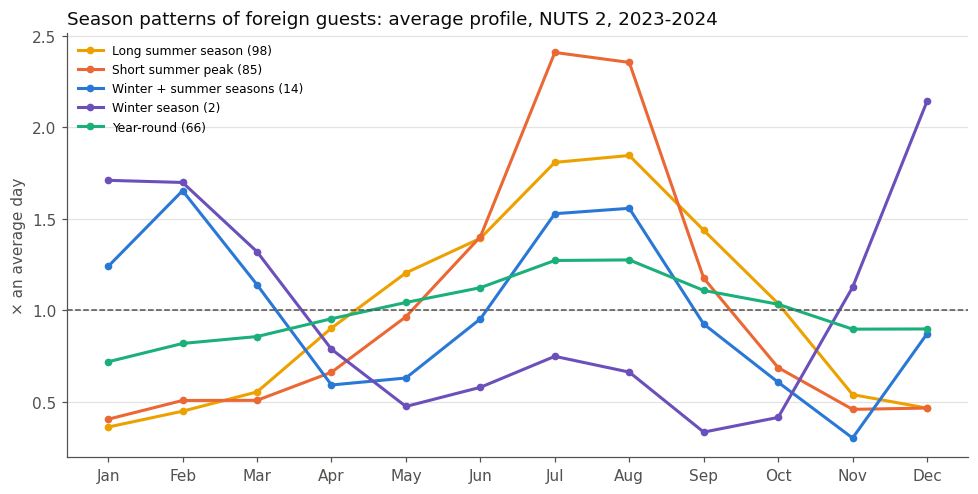

NUTS 2 regions by pattern and amplitude, 2023-2024:


AmplitudeClass                    Low  Medium  High  All
row_0    SeasonPattern                                  
Domestic Short summer peak          8      71    39  118
         Long summer season        10      32     4   46
         Winter + summer seasons    2       6     3   11
         Winter season              2       0     0    2
         Year-round                87       0     0   87
Foreign  Short summer peak          9      28    54   91
         Long summer season        11      51    30   92
         Winter + summer seasons    2      10     2   14
         Winter season              0       1     1    2
         Year-round                66       0     0   66
Total    Short summer peak         13      46    46  105
         Long summer season         9      51    13   73
         Winter + summer seasons    3       7     1   11
         Winter season              2       0     0    2
         Year-round                77       0     0   77
All                               301     303   193  797

In [7]:
seasonal = idx["SeasonCount"] != "No clear season"
dev = fac - 1
unit = dev.div(np.sqrt((dev ** 2).sum(axis=1)), axis=0)          # shape only

def silhouette_values(D, labels):
    s = []
    for i in range(len(labels)):
        same = labels == labels[i]; same[i] = False
        a = D[i, same].mean() if same.any() else 0.0
        b = min(D[i, labels == c].mean() for c in set(labels) if c != labels[i])
        s.append((b - a) / max(a, b))
    return np.array(s)

base_keys = [k for k in unit.index if k[1] == "Foreign" and k[2] == "2023-2024"
             and regions.at[k[0], "NUTSLevel"] == 2 and seasonal.loc[k]]
Xb = unit.loc[base_keys].to_numpy()
Zw, Db = linkage(Xb, method="ward"), squareform(pdist(Xb))
sil = {k: silhouette_values(Db, fcluster(Zw, k, "maxclust")).mean() for k in range(3, 9)}
display(pd.Series(sil, name="mean silhouette (foreign, NUTS 2)").round(3).to_frame().T)
K_BEST = max(sil, key=sil.get)
lab = fcluster(Zw, K_BEST, "maxclust")
centres_unit = pd.DataFrame(Xb, columns=MONTH_NAMES).groupby(lab).mean()
centres_fac = fac.loc[base_keys].reset_index(drop=True).groupby(lab).mean()

def name_of(c):
    if c[["December", "January", "February"]].mean() >= 1:
        return "Winter + summer seasons" if c[["July", "August"]].mean() >= 1 else "Winter season"
    return "Short summer peak" if (c >= 1).sum() <= 4 else "Long summer season"
CNAME = {k: name_of(centres_fac.loc[k]) for k in centres_fac.index}
PATTERNS = ["Short summer peak", "Long summer season", "Winter + summer seasons", "Winter season", "Year-round"]
# Groups that get the same name are merged (the name, not the cluster number, is the pattern).
names_b = np.array([CNAME[l] for l in lab])
centres_unit = pd.DataFrame(Xb, columns=MONTH_NAMES).groupby(names_b).mean()
centres_fac = fac.loc[base_keys].reset_index(drop=True).groupby(names_b).mean()

# Assign every seasonal profile to the nearest centre (Euclidean distance on the unit-shape vectors).
C = centres_unit.to_numpy()
nearest = np.argmin(((unit[seasonal].to_numpy()[:, None, :] - C[None, :, :]) ** 2).sum(axis=2), axis=1)
pat = pd.Series("Year-round", index=idx.index)
pat[seasonal] = [centres_unit.index[j] for j in nearest]
idx["SeasonPattern"] = pd.Categorical(pat, categories=PATTERNS)
idx["AmplitudeClass"] = pd.Categorical(pd.cut(idx["Gini"], [0, 0.17, 0.33, 1.01], right=False, labels=["Low", "Medium", "High"]),
                                       categories=["Low", "Medium", "High"])
agree = (idx.loc[base_keys, "SeasonPattern"].astype(str).values == names_b).mean()
print(f"nearest-centre labels agree with the Ward groups for {agree:.0%} of the foreign NUTS 2 profiles they were built from")

print(f"{K_BEST} shape groups:", CNAME, "-> patterns:", sorted(set(CNAME.values())))
fig, ax = plt.subplots(figsize=(9, 4.6), dpi=110)
COLORS = {"Short summer peak": "#eb6834", "Long summer season": "#eda100", "Winter + summer seasons": "#2a78d6",
          "Winter season": "#6b4fbb", "Year-round": "#1baf7a"}
for k, cf in centres_fac.iterrows():
    ax.plot(range(12), cf.values, color=COLORS[k], lw=2, marker="o", ms=4, label=f"{k} ({(names_b == k).sum()})")
yr = fac.loc[[k for k in fac.index if k[1] == "Foreign" and k[2] == "2023-2024" and regions.at[k[0], "NUTSLevel"] == 2 and not seasonal.loc[k]]]
ax.plot(range(12), yr.mean().values, color=COLORS["Year-round"], lw=2, marker="o", ms=4, label=f"Year-round ({len(yr)})")
ax.axhline(1, color=MUTED, lw=1, ls="--"); ax.set_xticks(range(12), SHORT)
style(ax, "Season patterns of foreign guests: average profile, NUTS 2, 2023-2024", "× an average day")
ax.legend(frameon=False, fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

tab = idx.xs("2023-2024", level="Period")
tab = tab[tab.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2]
print("NUTS 2 regions by pattern and amplitude, 2023-2024:")
display(pd.crosstab([tab.index.get_level_values("ResidenceCountry"), tab["SeasonPattern"]], tab["AmplitudeClass"], margins=True))

## B6. Eurostat's simple indicators

Eurostat's article *Tourism statistics – seasonality at regional level* (Statistics Explained) uses plain indicators that are easy to map. They are added so the findings can be compared with Eurostat's:

* **Top2Share** — % of the year's nights in the two busiest months (Eurostat's main measure; EU average 31% in 2024). Computed, as there, on monthly **totals**, not nights per day.
* **TopMonth** / **Top2Months** — the busiest month, and the two busiest months.
* **PeakIntensity** — nights per day in the busiest month per 1,000 inhabitants (tourism intensity in the peak month).
* **PeakDensity** — nights per day in the busiest month per km² (tourism density in the peak month).

Per year from the published months; for `2023-2024` the average of the usable years. Intensity and density need population and area (Stage 1, step 5b).

In [8]:
pop_y = df.drop_duplicates(["NUTSCode", "Year"]).set_index(["NUTSCode", "Year"])["Population"]
area_r = df.drop_duplicates("NUTSCode").set_index("NUTSCode")["AreaKm2"]
nv = nights[volume_ok]
top2 = np.sort(nv.to_numpy(), axis=1)[:, -2:].sum(axis=1) / nv.sum(axis=1).to_numpy() * 100
pk = nv.to_numpy().argmax(axis=1)
peak_npd = npd[volume_ok].to_numpy()[np.arange(len(nv)), pk]
codes_, years_ = nv.index.get_level_values("NUTSCode"), nv.index.get_level_values("Year")
simple = pd.DataFrame({
    "Top2Share": top2,
    "TopMonth": [MONTH_NAMES[i] for i in pk],
    "Top2Months": [" + ".join(MONTH_NAMES[j] for j in sorted(np.argsort(-r)[:2])) for r in nv.to_numpy()],
    "PeakIntensity": peak_npd / pop_y.reindex(list(zip(codes_, years_))).to_numpy() * 1000,
    "PeakDensity": peak_npd / area_r.reindex(codes_).to_numpy()}, index=nv.index)
simple_y = simple.copy()
simple_y.index = simple_y.index.set_levels(simple_y.index.levels[1].astype(str), level="Year")
simple_y = simple_y.reorder_levels(["NUTSCode", "ResidenceCountry", "Year"]).rename_axis(["NUTSCode", "ResidenceCountry", "Period"])
num = simple_y[["Top2Share", "PeakIntensity", "PeakDensity"]].groupby(level=["NUTSCode", "ResidenceCountry"]).mean()
# busiest months of the 2023-2024 profile of monthly totals
avg_tot = nv.div(nv.sum(axis=1), axis=0).groupby(level=["NUTSCode", "ResidenceCountry"]).mean()
num["TopMonth"] = [MONTH_NAMES[i] for i in avg_tot.to_numpy().argmax(axis=1)]
num["Top2Months"] = [" + ".join(MONTH_NAMES[j] for j in sorted(np.argsort(-r)[:2])) for r in avg_tot.to_numpy()]
num = num.assign(Period="2023-2024").set_index("Period", append=True)
simple_all = pd.concat([simple_y, num]).sort_index()
idx = idx.join(simple_all.round({"Top2Share": 2, "PeakIntensity": 2, "PeakDensity": 3}))

eu_cc = ["BE", "BG", "CZ", "DK", "DE", "EE", "IE", "EL", "ES", "FR", "HR", "IT", "CY", "LV", "LT", "LU", "HU", "MT", "NL",
         "AT", "PL", "PT", "RO", "SI", "SK", "FI", "SE"]
eu24 = nights.xs((2024, "Total"), level=["Year", "ResidenceCountry"]).reindex(eu_cc).sum()
print(f"check against Eurostat: EU-27 top-2 share 2024 = {100 * np.sort(eu24.to_numpy())[-2:].sum() / eu24.sum():.1f}% "
      f"(sum of the 27 countries; Eurostat's article reports 31%)")
t24 = idx.xs(("Total", "2024"), level=["ResidenceCountry", "Period"])
t24 = t24[t24.index.map(regions["NUTSLevel"]) == 2]
print(f"NUTS 2, all guests, 2024: rank correlation Top2Share ~ Gini {t24['Top2Share'].corr(t24['Gini'], method='spearman'):.2f}; "
      f"~ S_R {t24['Top2Share'].corr(t24['SR'], method='spearman'):.2f}")
display(t24.nlargest(5, "Top2Share").assign(Region=lambda x: x.index.map(regions["Region"]))[["Region", "Top2Share", "Top2Months", "Gini", "PeakIntensity", "PeakDensity"]])

check against Eurostat: EU-27 top-2 share 2024 = 31.3% (sum of the 27 countries; Eurostat's article reports 31%)
NUTS 2, all guests, 2024: rank correlation Top2Share ~ Gini 0.97; ~ S_R 0.95


,Region,Top2Share,Top2Months,Gini,PeakIntensity,PeakDensity
NUTSCode,,,,,,
RO22,Sud-Est,65.97,July + August,0.6115,32.38,2.122
BG34,Yugoiztochen,60.07,July + August,0.6308,110.74,5.320
ITF6,Calabria,58.76,July + August,0.6052,46.00,5.556
HR03,Jadranska Hrvatska,57.68,July + August,0.6121,650.77,34.516
BG33,Severoiztochen,56.93,July + August,0.5897,75.99,4.286


# C. Foreign guests

## C1. Foreign share

**PrcForeign** = foreign ÷ all nights (annual, per period). **ForeignGroup**: *Mainly domestic* < 40%, *Mixed* 40–70%, *Mainly foreign* ≥ 70% (unchanged from the platform version, compared below with the terciles of this dataset).

In [9]:
ann = annual.unstack("ResidenceCountry")
fs = (100 * ann["Foreign"] / ann["Total"]).rename("PrcForeign")
fs_y = fs.copy(); fs_y.index = fs_y.index.set_levels(fs_y.index.levels[1].astype(str), level="Year")
fs_avg = (100 * ann["Foreign"].groupby(level="NUTSCode").sum() / ann["Total"].groupby(level="NUTSCode").sum())
foreign_share = pd.concat([fs_y.rename_axis(["NUTSCode", "Period"]),
                           fs_avg.to_frame("PrcForeign").assign(Period="2023-2024").set_index("Period", append=True)["PrcForeign"]]).round(2)
FG = ["Mainly domestic", "Mixed", "Mainly foreign"]
foreign_group = pd.cut(foreign_share, [-np.inf, 40, 70, np.inf], right=False, labels=FG)
x_ = foreign_share.xs("2023-2024", level="Period")
x_ = x_[x_.index.map(regions["NUTSLevel"]) == 2]
print(f"NUTS 2, 2023-2024: terciles of the foreign share {np.percentile(x_, 100/3):.1f} / {np.percentile(x_, 200/3):.1f}%;",
      foreign_group.xs("2023-2024", level="Period").reindex(x_.index).value_counts().reindex(FG).to_dict())

NUTS 2, 2023-2024: terciles of the foreign share 21.0 / 45.3%; {'Mainly domestic': 167, 'Mixed': 70, 'Mainly foreign': 31}


## C2. Do foreign guests make the year more or less seasonal?

Three complementary measures per region (and per period), all computed on nights per day:

**(a) Timing counterfactual — "what if foreign guests travelled like domestic guests?"** Index of all nights minus the index if the foreign nights kept their total but followed the domestic monthly profile. Computed with **Gini (`ForeignTimingEffectGini`, main)** and with S_R (`ForeignTimingEffectSR`). Positive = foreign timing sharpens the year; negative = smooths it. It is an accounting comparison of today's year, not a causal effect.

**(b) Gini decomposition** (Lerman & Yitzhaki 1985; Fernández-Morales et al. 2016): total Gini = Σ share × Gini correlation × own Gini over the domestic and foreign segments. For the foreign segment: `S_F`, `G_F`, `GiniCorrF` (Γ_F, how far foreign peaks coincide with the region's peaks), and

* **`RME_F`** = S_F·Γ_F·G_F / G − S_F: relative effect on the Gini of a small, evenly spread increase in foreign nights — an elasticity: the % change in the region's Gini when every month's foreign nights grow by 1%;
* **`AME_F`** = S_F·(Γ_F·G_F − G): the same in absolute Gini points. Unlike RME it is not inflated where the Gini is tiny (cities).

Both answer the *marginal* question — would **more** foreign demand flatten the year? — which (a) does not.

**(c) Class (`ForeignTimingClass`)** from (a) on Gini. *Sharpens* / *Smooths* = the 2023–2024 effect beyond ±δ **and** the same sign in 2023 and in 2024; otherwise *No clear effect*. δ is the larger of two numbers:

* the effect's **own noise** — the median absolute difference of the effect between 2023 and 2024 across regions (a change smaller than this is indistinguishable from year-to-year movement);
* a **smallest effect worth reporting** of 0.01 Gini points — about one twentieth of the typical region's Gini.

**(d) Four types (`ForeignEffectType`)**, following the logic of Fernández-Morales, Cisneros-Martínez & McCabe (2016). Their *relative marginal effect* RME_F says whether more foreign demand would lower (favourable, RME_F ≤ −0.02) or raise (unfavourable, ≥ +0.02) the region's Gini; the decomposition says **why**. RME_F < 0 exactly when Γ_F·G_F < G (the foreign contribution to concentration is smaller than its share), which can happen in two ways:

| Type | Rule | Meaning (paper's wording) |
|---|---|---|
| **Flatter foreign demand** | RME_F ≤ −0.02 and G_F < G | foreign guests' own year is less concentrated than the region's — a lasting stabiliser |
| **Off-peak foreign demand** | RME_F ≤ −0.02 and G_F ≥ G | foreign demand is itself seasonal, but its peaks fall outside the region's busy months (low Γ_F) — a *compensation* effect, which lasts only while it offsets the other guests |
| **Neutral foreign demand** | −0.02 < RME_F < 0.02, or the sign changes between 2023 and 2024 | little marginal effect |
| **Peak-reinforcing foreign demand** | RME_F ≥ +0.02 | foreign demand is concentrated in the region's own peak months (Γ_F·G_F > G) |

The ±0.02 cut-off is the paper's. The sign must hold in 2023 and 2024, as for the other classes.

The same rule on S_R gives `ForeignTimingClassSR`. **`MarginalClass`** applies it to `AME_F`, with 0.005 as the smallest effect (doubling foreign nights would move the Gini by less than half a point). Regions with one usable year only are classed on the ±δ rule alone.

Both guest groups need a usable series (A1) in the same year.

In [10]:
def gini_corr(x, y):
    """Gini correlation of x with y: cov(x, rank of y) / cov(x, rank of x)."""
    rx = np.empty(T); rx[np.argsort(x, kind="stable")] = np.arange(1, T + 1)
    ry = np.empty(T); ry[np.argsort(y, kind="stable")] = np.arange(1, T + 1)
    return np.cov(x, ry, bias=True)[0, 1] / np.cov(x, rx, bias=True)[0, 1]

def effects(dv, fv):
    """dv, fv: domestic and foreign nights per day by month (12 values each)."""
    y = dv + fv
    f_cf = fv.sum() * dv / dv.sum()                                   # foreign nights, domestic timing
    G, GF, GD = gini(y), gini(fv), gini(dv)
    SF = fv.sum() / y.sum()
    GC = gini_corr(fv, y)
    GCd = gini_corr(dv, y)
    assert abs(G - ((1 - SF) * GCd * GD + SF * GC * GF)) < 1e-9          # decomposition holds exactly
    return {"ForeignTimingEffectSR": s_r(y) - s_r(dv + f_cf), "ForeignTimingEffectGini": G - gini(dv + f_cf),
            "G_Y": G, "S_F": SF, "G_F": GF, "G_D": GD, "GiniCorrF": GC, "RME_F": SF * GC * GF / G - SF, "AME_F": SF * (GC * GF - G)}

ok_d = volume_ok.xs("Domestic", level="ResidenceCountry"); ok_f = volume_ok.xs("Foreign", level="ResidenceCountry")
both_ok = ok_d & ok_f.reindex(ok_d.index, fill_value=False)
pd_dom, pd_for = npd.xs("Domestic", level="ResidenceCountry"), npd.xs("Foreign", level="ResidenceCountry")

rows = []
for (code, year) in both_ok[both_ok].index:
    rows.append({"NUTSCode": code, "Period": str(year), **effects(pd_dom.loc[(code, year)].to_numpy(), pd_for.loc[(code, year)].to_numpy())})
# 2023-2024: average nights per day of the usable years (both groups usable in the same years)
for code, g in both_ok[both_ok].groupby(level="NUTSCode"):
    yrs = g.index.get_level_values("Year")
    dv = pd_dom.loc[[(code, y) for y in yrs]].to_numpy().mean(axis=0)
    fv = pd_for.loc[[(code, y) for y in yrs]].to_numpy().mean(axis=0)
    rows.append({"NUTSCode": code, "Period": "2023-2024", "YearsUsed": len(yrs), **effects(dv, fv)})
fe = pd.DataFrame(rows).set_index(["NUTSCode", "Period"]).sort_index()

# Noise of the effect itself: median |2024 - 2023| across regions with both years.
wy = fe["ForeignTimingEffectSR"].unstack("Period")[["2023", "2024"]].dropna()
DELTA = float((wy["2024"] - wy["2023"]).abs().median())
wyg = fe["ForeignTimingEffectGini"].unstack("Period")[["2023", "2024"]].dropna()
DELTA_G = float((wyg["2024"] - wyg["2023"]).abs().median())
print(f"noise of the effect (median |2024 - 2023|): S_R {DELTA:.4f}, Gini {DELTA_G:.4f}")

TYPES = ["Flatter foreign demand", "Off-peak foreign demand", "Neutral foreign demand", "Peak-reinforcing foreign demand"]
MIN_EFFECT = {"ForeignTimingEffectSR": 0.01, "ForeignTimingEffectGini": 0.01, "AME_F": 0.005}
def noise(col):
    w_ = fe[col].unstack("Period")[["2023", "2024"]].dropna()
    return float((w_["2024"] - w_["2023"]).abs().median())
DELTAS = {c: max(noise(c), m) for c, m in MIN_EFFECT.items()}
print("thresholds delta = max(noise, smallest effect):", {c: (round(noise(c), 4), round(d_, 4)) for c, d_ in DELTAS.items()})

def classify(effect_col, delta, labels=("Smooths", "No clear effect", "Sharpens")):
    e = fe[effect_col]
    w = e.unstack("Period")
    same_sign = np.sign(w["2023"]) == np.sign(w["2024"])
    stable = same_sign.where(w[["2023", "2024"]].notna().all(axis=1), True)      # one usable year: sign rule not applicable
    cls = pd.Series(labels[1], index=e.index)
    for code, per in e.index:
        v = e.loc[(code, per)]
        ok_sign = bool(stable.get(code, True)) if per == "2023-2024" else True
        if v > delta and ok_sign:
            cls.loc[(code, per)] = labels[2]
        elif v < -delta and ok_sign:
            cls.loc[(code, per)] = labels[0]
    return pd.Categorical(cls, categories=list(labels))
fe["ForeignTimingClass"] = classify("ForeignTimingEffectGini", DELTAS["ForeignTimingEffectGini"])
fe["ForeignTimingClassSR"] = classify("ForeignTimingEffectSR", DELTAS["ForeignTimingEffectSR"])
fe["MarginalClass"] = classify("AME_F", DELTAS["AME_F"], ("More foreign nights flatten", "Little marginal effect", "More foreign nights sharpen"))

# Four types (Fernández-Morales et al. 2016): RME_F with their cut-off of +/-0.02 and stable sign, then the mechanism.
rme_dir = classify("RME_F", 0.02, ("favourable", "neutral", "unfavourable"))
fe["ForeignEffectType"] = pd.Categorical(np.select(
    [(rme_dir == "favourable") & (fe["G_F"] < fe["G_Y"]),
     (rme_dir == "favourable") & (fe["G_F"] >= fe["G_Y"]),
     rme_dir == "unfavourable"],
    ["Flatter foreign demand", "Off-peak foreign demand", "Peak-reinforcing foreign demand"], "Neutral foreign demand"),
    categories=TYPES)
fe = fe.round(4)

n2e = fe.xs("2023-2024", level="Period"); n2e = n2e[n2e.index.map(regions["NUTSLevel"]) == 2]
print(f"NUTS 2 regions with both guest groups usable: {len(n2e)}")
display(pd.crosstab(n2e["ForeignTimingClass"], n2e["ForeignTimingClassSR"], margins=True)
        .rename_axis(index="class on Gini (main)", columns="class on S_R"))
display(pd.crosstab(n2e["ForeignTimingClass"], n2e["MarginalClass"], margins=True))
print("Four types (RME, Fernández-Morales et al. 2016) against the three timing classes:")
display(pd.crosstab(n2e["ForeignEffectType"], n2e["ForeignTimingClass"], margins=True))

noise of the effect (median |2024 - 2023|): S_R 0.0037, Gini 0.0035
thresholds delta = max(noise, smallest effect): {'ForeignTimingEffectSR': (0.0037, 0.01), 'ForeignTimingEffectGini': (0.0035, 0.01), 'AME_F': (0.0021, 0.005)}
NUTS 2 regions with both guest groups usable: 264


class on S_R,Smooths,No clear effect,Sharpens,All
class on Gini (main),,,,
Smooths,43,7,0,50
No clear effect,2,79,8,89
Sharpens,2,4,119,125
All,47,90,127,264


MarginalClass,More foreign nights flatten,Little marginal effect,More foreign nights sharpen,All
ForeignTimingClass,,,,
Smooths,45,2,3,50
No clear effect,8,70,11,89
Sharpens,0,3,122,125
All,53,75,136,264


Four types (RME, Fernández-Morales et al. 2016) against the three timing classes:


ForeignTimingClass,Smooths,No clear effect,Sharpens,All
ForeignEffectType,,,,
Flatter foreign demand,42,12,0,54
Off-peak foreign demand,3,3,0,6
Neutral foreign demand,2,57,5,64
Peak-reinforcing foreign demand,3,17,120,140
All,50,89,125,264


# D. Geography groups

From the residents' shares of Stage 1 (Eurostat urban–rural thresholds on the rural share; 0 / under 50% / 50%+ for coastal, inland mountain, island). Unchanged from the platform version; they describe where people live, not where guests stay.

In [11]:
shares = df.drop_duplicates("NUTSCode").set_index("NUTSCode")[["PrcCities", "PrcRural", "PrcCoastal", "PrcInlandMountain", "PrcIsland"]]
def group3(s, cats):
    return pd.Series(pd.Categorical(np.select([s == 0, s < 50], cats[:2], cats[2]), categories=cats), index=s.index).where(s.notna())
geo = shares.copy()
geo["UrbanGroup"] = pd.Series(pd.Categorical(np.select([shares["PrcRural"] >= 50, shares["PrcRural"] <= 20],
                                                       ["Predominantly rural", "Predominantly urban"], "Intermediate"),
                                             categories=["Predominantly urban", "Intermediate", "Predominantly rural"]),
                              index=shares.index).where(shares["PrcRural"].notna())
geo["CoastalGroup"] = group3(shares["PrcCoastal"], ["Non-coastal", "Partly coastal", "Predominantly coastal"])
geo["InlandMountainGroup"] = group3(shares["PrcInlandMountain"], ["Non-inland mountain", "Partly inland mountain", "Predominantly inland mountain"])
geo["IslandGroup"] = group3(shares["PrcIsland"], ["Non-island", "Partly island", "Predominantly island"])
geo[regions["NUTSLevel"].reindex(geo.index) == 2][["UrbanGroup", "CoastalGroup", "InlandMountainGroup", "IslandGroup"]].apply(lambda s: s.value_counts()).fillna("")

,UrbanGroup,CoastalGroup,InlandMountainGroup,IslandGroup
Intermediate,136.0,,,
Non-coastal,,141.0,,
Non-inland mountain,,,162.0,
Non-island,,,,235.0
Partly coastal,,51.0,,
Partly inland mountain,,,56.0,
Partly island,,,,2.0
Predominantly coastal,,68.0,,
Predominantly inland mountain,,,39.0,
Predominantly island,,,,21.0


# E. Save

In [12]:
yu = years_used.rename("YearsUsed").reset_index().assign(Period="2023-2024").set_index(["NUTSCode", "ResidenceCountry", "Period"])
out = idx.join(yu)
out["YearsUsed"] = out["YearsUsed"].fillna(1).astype(int)
nights_y = annual.copy(); nights_y.index = nights_y.index.set_levels(nights_y.index.levels[1].astype(str), level="Year")
nights_y = nights_y.reorder_levels(["NUTSCode", "ResidenceCountry", "Year"]).rename_axis(["NUTSCode", "ResidenceCountry", "Period"])
ok_y = volume_ok.copy(); ok_y.index = ok_y.index.set_levels(ok_y.index.levels[1].astype(str), level="Year")
ok_y = ok_y.reorder_levels(["NUTSCode", "ResidenceCountry", "Year"]).rename_axis(["NUTSCode", "ResidenceCountry", "Period"])
avg_n = nights_y[ok_y.reindex(nights_y.index, fill_value=False)].groupby(level=["NUTSCode", "ResidenceCountry"]).mean()
avg_n = avg_n.to_frame("Nights").assign(Period="2023-2024").set_index("Period", append=True)["Nights"]
out["Nights"] = pd.concat([nights_y, avg_n]).reindex(out.index).round(0)
lr = low_rel.copy(); lr.index = lr.index.set_levels(lr.index.levels[1].astype(str), level="Year")
lr = lr.reorder_levels(["NUTSCode", "ResidenceCountry", "Year"]).rename_axis(["NUTSCode", "ResidenceCountry", "Period"])
lr_any = lr.groupby(level=["NUTSCode", "ResidenceCountry"]).any().to_frame("x").assign(Period="2023-2024").set_index("Period", append=True)["x"]
out["LowReliability"] = pd.concat([lr, lr_any]).reindex(out.index).fillna(False).astype(int)
out = out.reset_index()
out = out.merge(regions, left_on="NUTSCode", right_index=True)
out["PrcForeign"] = [foreign_share.get((c, p), np.nan) for c, p in zip(out["NUTSCode"], out["Period"])]
out["ForeignGroup"] = pd.Categorical(pd.cut(out["PrcForeign"], [-np.inf, 40, 70, np.inf], right=False, labels=FG), categories=FG)
out = out.merge(geo, left_on="NUTSCode", right_index=True, how="left")
COLS = ["Region", "NUTSCode", "NUTSLevel", "ParentRegion", "Country", "ResidenceCountry", "Period", "YearsUsed", "Nights", "LowReliability",
        "Gini", "SR", "Season75", "SeasonalityIndicator", "PeakTroughRatio", "PeakMonth", "TroughMonth", "JulAugFactor", "WinterFactor",
        "SeasonalityPercentile", "SRPercentile", "RankGap", "SpreadRatio", "SeasonCount", "SeasonPattern", "AmplitudeClass",
        "Top2Share", "TopMonth", "Top2Months", "PeakIntensity", "PeakDensity",
        "PrcForeign", "ForeignGroup", "PrcCities", "PrcRural", "UrbanGroup", "PrcCoastal", "CoastalGroup",
        "PrcInlandMountain", "InlandMountainGroup", "PrcIsland", "IslandGroup"]
out = out[COLS].sort_values(["Country", "NUTSCode", "ResidenceCountry", "Period"])
out.to_csv("data/ready/tour_occ_nin2m_indices.csv", index=False, encoding="utf-8-sig")

def long_(w, name):
    return w.rename_axis(columns="Month").reset_index().melt(id_vars=["NUTSCode", "ResidenceCountry", "Period"], var_name="Month", value_name=name)
KP = ["NUTSCode", "ResidenceCountry", "Period", "Month"]
pr = long_(profiles, "Share").merge(long_(fac, "Factor"), on=KP).merge(long_(prc75, "Prc75Flag"), on=KP)
pr["Month"] = pd.Categorical(pr["Month"], categories=MONTH_NAMES, ordered=True)
pr = pr.sort_values(KP)
pr["Share"], pr["Factor"] = pr["Share"].round(5), pr["Factor"].round(4)
pr.to_csv("data/ready/tour_occ_nin2m_profiles.csv", index=False, encoding="utf-8-sig")

fe_out = fe.reset_index().merge(regions[["Region", "NUTSLevel", "Country"]], left_on="NUTSCode", right_index=True)
fe_out["YearsUsed"] = fe_out["YearsUsed"].fillna(1).astype(int)
fe_out = fe_out[["Region", "NUTSCode", "NUTSLevel", "Country", "Period", "YearsUsed", "ForeignTimingEffectSR", "ForeignTimingEffectGini",
                 "ForeignTimingClass", "ForeignTimingClassSR", "G_Y", "S_F", "G_F", "G_D", "GiniCorrF", "RME_F", "AME_F", "MarginalClass",
                 "ForeignEffectType"]]
fe_out.to_csv("data/ready/tour_occ_nin2m_foreign_effect.csv", index=False, encoding="utf-8-sig")
print(f"indices: {len(out):,} rows x {out.shape[1]}; profiles: {len(pr):,} rows; foreign effect: {len(fe_out):,} rows")
print(f"constants used: MIN_NIGHTS={MIN_NIGHTS}, K_BEST={K_BEST}, deltas={ {k: round(v, 4) for k, v in DELTAS.items()} }")

indices: 3,574 rows x 42; profiles: 42,888 rows; foreign effect: 1,182 rows
constants used: MIN_NIGHTS=10000, K_BEST=4, deltas={'ForeignTimingEffectSR': 0.01, 'ForeignTimingEffectGini': 0.01, 'AME_F': 0.005}


In [13]:
chk = pd.read_csv("data/ready/tour_occ_nin2m_indices.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])
chk_fe = pd.read_csv("data/ready/tour_occ_nin2m_foreign_effect.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])
checks = {
    "unique region x group x period": not chk.duplicated(["NUTSCode", "ResidenceCountry", "Period"]).any(),
    "Gini and S_R in range": chk["Gini"].between(0, 11 / 12).all() and chk["SR"].between(0, 1).all(),
    "profiles sum to 1": pr.groupby(["NUTSCode", "ResidenceCountry", "Period"])["Share"].sum().sub(1).abs().lt(1e-3).all(),
    "Season75 = flagged months": (pr.groupby(["NUTSCode", "ResidenceCountry", "Period"])["Prc75Flag"].sum()
                                  .reindex(chk.set_index(["NUTSCode", "ResidenceCountry", "Period"]).index).values == chk["Season75"].values).all(),
    "no confidential month used": not chk.merge(flags.reset_index().assign(Period=lambda x: x["Year"].astype(str)),
                                                on=["NUTSCode", "ResidenceCountry", "Period"])["C"].any(),
    "every pattern named": chk["SeasonPattern"].notna().all(),
    "foreign share 0-100": chk["PrcForeign"].dropna().between(0, 100).all(),
    "S_F in 0-1": chk_fe["S_F"].between(0, 1).all(),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())

,passed
unique region x group x period,True
Gini and S_R in range,True
profiles sum to 1,True
Season75 = flagged months,True
no confidential month used,True
every pattern named,True
foreign share 0-100,True
S_F in 0-1,True


# Appendix — robustness

* **R1** — what the calendar adjustment changes;
* **R2** — are the patterns stable between 2023 and 2024, and how distinct are they;
* **R3** — sensitivity of the season count (SpreadRatio cut-offs; the run rule used as a check);
* **R4** — the foreign-effect classes: noise, sign stability, Gini vs S_R.

In [14]:
# R1. Nights per day vs monthly totals (NUTS 2, all guest groups, 2023-2024 average profiles)
raw_share = nights[volume_ok].div(nights[volume_ok].sum(axis=1), axis=0).groupby(level=["NUTSCode", "ResidenceCountry"]).mean()
cmp = pd.DataFrame({"SR_per_day": [s_r(r) for r in avg.to_numpy()], "SR_monthly": [s_r(r) for r in raw_share.reindex(avg.index).to_numpy()],
                    "Gini_per_day": [gini(r) for r in avg.to_numpy()], "Gini_monthly": [gini(r) for r in raw_share.reindex(avg.index).to_numpy()],
                    "Feb_per_day": avg["February"].to_numpy() * T, "Feb_monthly": raw_share.reindex(avg.index)["February"].to_numpy() * T},
                   index=avg.index)
cmp = cmp[cmp.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2]
print("R1. Effect of the calendar adjustment (NUTS 2, 2023-2024 profiles):")
display(pd.DataFrame({"median change": [(cmp["SR_per_day"] - cmp["SR_monthly"]).median(), (cmp["Gini_per_day"] - cmp["Gini_monthly"]).median(),
                                        (cmp["Feb_per_day"] - cmp["Feb_monthly"]).median()],
                      "max |change|": [(cmp["SR_per_day"] - cmp["SR_monthly"]).abs().max(), (cmp["Gini_per_day"] - cmp["Gini_monthly"]).abs().max(),
                                       (cmp["Feb_per_day"] - cmp["Feb_monthly"]).abs().max()]},
                     index=["S_R", "Gini", "February factor"]).round(4))
print(f"rank correlation S_R per day ~ monthly: {cmp['SR_per_day'].corr(cmp['SR_monthly'], method='spearman'):.4f}")

R1. Effect of the calendar adjustment (NUTS 2, 2023-2024 profiles):


,median change,max |change|
S_R,-0.0034,0.0082
Gini,-0.0034,0.0076
February factor,0.0452,0.1408


rank correlation S_R per day ~ monthly: 0.9998


In [15]:
# R2. Pattern stability and distinctness
pp = idx["SeasonPattern"].unstack("Period")
pp = pp[pp.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2].dropna()
print("R2a. Share of NUTS 2 profiles with the same pattern in 2023 and 2024, by guest group:")
display((pp["2023"] == pp["2024"]).groupby(level="ResidenceCountry").mean().round(2).to_frame("same pattern"))
print("     ... by 2023-2024 pattern (all guest groups):")
display((pp["2023"] == pp["2024"]).groupby(pp["2023-2024"], observed=True).agg(["size", "mean"]).round(2))
sv = silhouette_values(Db, lab)
print(f"R2b. Silhouette of the foreign shape groups: mean {sv.mean():.2f} (> 0.5 strong, 0.25-0.5 reasonable, < 0.25 weak / a continuum)")
display(pd.Series(sv).groupby(names_b).agg(["size", "mean"]).round(2))

R2a. Share of NUTS 2 profiles with the same pattern in 2023 and 2024, by guest group:


,same pattern
ResidenceCountry,
Domestic,0.92
Foreign,0.89
Total,0.91


     ... by 2023-2024 pattern (all guest groups):


,size,mean
2023-2024,,
Short summer peak,311,0.93
Long summer season,206,0.86
Winter + summer seasons,36,0.92
Winter season,4,1.00
Year-round,229,0.90


R2b. Silhouette of the foreign shape groups: mean 0.23 (> 0.5 strong, 0.25-0.5 reasonable, < 0.25 weak / a continuum)


,size,mean
Long summer season,98,0.13
Short summer peak,85,0.32
Winter + summer seasons,14,0.32
Winter season,2,0.40


In [16]:
# R3. Number of seasons: sensitivity of the SpreadRatio cut-offs, and of the run rule used as a check
s3 = idx.xs("2023-2024", level="Period")
s3 = s3[(s3.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2) & (s3["Gini"] >= 0.15)]
rows3 = {}
for lo in (0.5, 0.6, 0.7):
    for hi in (0.85, 0.9, 0.95):
        r_ = s3["SpreadRatio"]
        rows3[(lo, hi)] = {"two seasons": int((r_ < lo).sum()), "main + secondary": int(((r_ >= lo) & (r_ < hi)).sum()),
                           "one season": int((r_ >= hi).sum())}
print("R3a. NUTS 2 profiles (all guest groups, Gini >= 0.15) by SpreadRatio cut-offs (0.6 / 0.9 used):")
display(pd.DataFrame(rows3).T.rename_axis(["two below", "one from"]))
rows3b = {}
for ratio in (0.15, 0.20, 0.25, 0.33, 0.50):
    sc = pd.Series([season_count(f, g, ratio=ratio) for f, g in zip(fac.to_numpy(), idx["Gini"])], index=idx.index).xs("2023-2024", level="Period").reindex(s3.index)
    rows3b[ratio] = {"two seasons (run rule)": int((sc == "Two seasons").sum()),
                     "of which SpreadRatio < 0.9": int(((sc == "Two seasons") & (s3["SpreadRatio"] < 0.9)).sum())}
print("R3b. Run rule: share of the larger season's excess needed for the smaller one (0.25 in B4):")
display(pd.DataFrame(rows3b).T)

R3a. NUTS 2 profiles (all guest groups, Gini >= 0.15) by SpreadRatio cut-offs (0.6 / 0.9 used):


two seasons  main + secondary  one season
two below one from                                           
0.5       0.85                5                62         500
          0.90                5                72         490
          0.95                5               110         452
0.6       0.85               30                37         500
          0.90               30                47         490
          0.95               30                85         452
0.7       0.85               38                29         500
          0.90               38                39         490
          0.95               38                77         452

R3b. Run rule: share of the larger season's excess needed for the smaller one (0.25 in B4):


,two seasons (run rule),of which SpreadRatio < 0.9
0.15,43,42
0.20,34,34
0.25,30,30
0.33,27,27
0.50,16,16


In [17]:
# R4. Foreign effect: noise, sign stability and agreement of the two indices
w4 = fe["ForeignTimingEffectGini"].unstack("Period")[["2023", "2024"]].dropna()
w4 = w4[w4.index.map(regions["NUTSLevel"]) == 2]
print(f"R4. NUTS 2 regions with both years: {len(w4)}; rank correlation 2023 ~ 2024 of the Gini effect: "
      f"{w4['2023'].corr(w4['2024'], method='spearman'):.2f}; same sign in {(np.sign(w4['2023']) == np.sign(w4['2024'])).mean():.0%}")
print(f"     noise (Gini) = {DELTA_G:.4f}, delta used = {DELTAS['ForeignTimingEffectGini']:.4f}; regions with |effect| > delta: "
      f"{(n2e['ForeignTimingEffectGini'].abs() > DELTAS['ForeignTimingEffectGini']).mean():.0%}")
for d_ in (0.005, 0.01, 0.02, 0.03):
    v_ = n2e["ForeignTimingEffectGini"]
    print(f"     with delta {d_}: sharpens {(v_ > d_).sum()}, smooths {(v_ < -d_).sum()} (before the sign rule)")
print(f"     rank correlation of the Gini and S_R effects: {n2e['ForeignTimingEffectGini'].corr(n2e['ForeignTimingEffectSR'], method='spearman'):.2f}")
print(f"     rank correlation of the Gini effect and AME_F: {n2e['ForeignTimingEffectGini'].corr(n2e['AME_F'], method='spearman'):.2f}")
print(f"     classes on Gini and on S_R agree in {(n2e['ForeignTimingClass'] == n2e['ForeignTimingClassSR']).mean():.0%} of regions")

R4. NUTS 2 regions with both years: 260; rank correlation 2023 ~ 2024 of the Gini effect: 0.97; same sign in 92%
     noise (Gini) = 0.0035, delta used = 0.0100; regions with |effect| > delta: 66%
     with delta 0.005: sharpens 134, smooths 69 (before the sign rule)
     with delta 0.01: sharpens 125, smooths 50 (before the sign rule)
     with delta 0.02: sharpens 94, smooths 34 (before the sign rule)
     with delta 0.03: sharpens 72, smooths 22 (before the sign rule)
     rank correlation of the Gini and S_R effects: 0.97
     rank correlation of the Gini effect and AME_F: 0.91
     classes on Gini and on S_R agree in 91% of regions
